In [1]:
import numpy as np
from hcipy import * 
import os
import sys
import matplotlib.pyplot as plt
import matplotlib.pylab as pylab
from scipy.optimize import curve_fit

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2
from psfGenerator import PsfGenerator

In [46]:
params = {'legend.fontsize': 'x-large',
          'figure.titlesize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)

def colorbar(mappable):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    import matplotlib.pyplot as plt
    last_axes = plt.gca()
    ax = mappable.axes
    fig = ax.figure
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(mappable, cax=cax)
    plt.sca(last_axes)
    return cbar

In [42]:
before = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/2026-03-31_075128_alfCir_adc_2dof_control/camsci1/camsci1_20260331075940674195803.fits')
after = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2026A/2026-03-31_080009_alfCir_adc_2dof_control/obs_pt1/camsci1_20260331080027053049361.fits')

In [43]:

print(before.size)
img = before
dim = np.sqrt(img.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(img.ravel(),pgrid)

before = Field(before.ravel(),pgrid)
after = Field(after.ravel(),pgrid)

1048576


In [44]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)
before = ADC.crop_image(before,extent=400,mask_diam=0)
after = ADC.crop_image(after,extent=400,mask_diam=0)

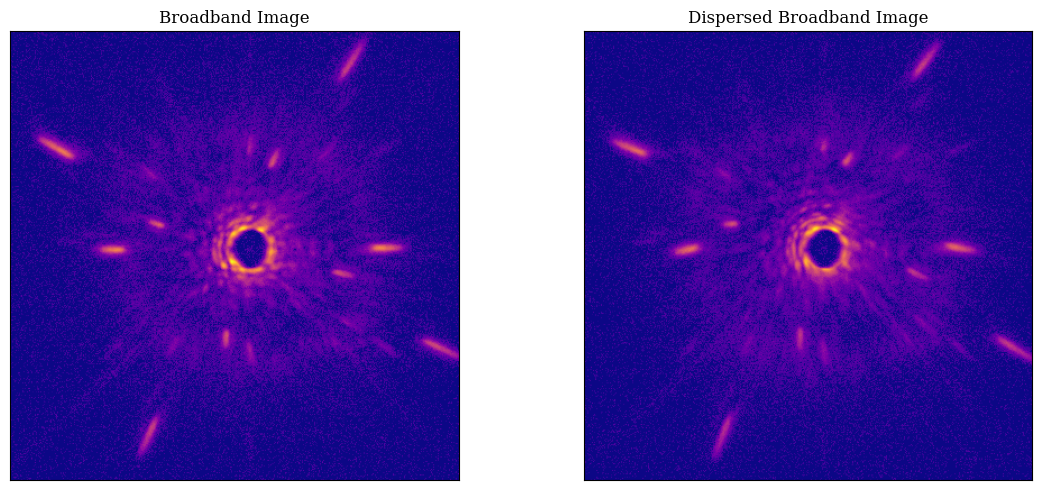

In [47]:
color = 'plasma'

fig = plt.figure()
plt.subplot(1,2,1)
imshow_field(np.sqrt(before),cmap=color)
#plt.colorbar()
plt.xticks([])
plt.yticks([])
plt.title('Broadband Image')
plt.subplot(1,2,2)
imshow_field(np.sqrt(after),cmap=color)
plt.xticks([])
plt.yticks([])
#plt.colorbar()
plt.title('Dispersed Broadband Image')
plt.tight_layout()
plt.show()

In [37]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/SPIE_26/onsky_satellitespots.png',dpi=300)